In [12]:
# Step 1: Import the required libraries

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# Step 2: Load the real-world dataset

data = pd.read_csv("Wine.csv")

X = data.drop("Class", axis=1)
y = data["Class"]

print("Dataset shape:", X.shape)
print("Target classes:", sorted(y.unique()))

Dataset shape: (178, 13)
Target classes: [np.int64(1), np.int64(2), np.int64(3)]


In [13]:
# Step 3: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)


In [14]:
# Step 4: Create and train the Decision Tree model

model = DecisionTreeClassifier(max_depth=3, random_state=42)

model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [15]:
# Step 5: Make predictions

y_pred = model.predict(X_test)

In [16]:
# Step 6: Evaluate the model

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))




Accuracy: 0.9444444444444444

Confusion Matrix:
[[11  1  0]
 [ 0 14  0]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.92      0.96        12
           2       0.88      1.00      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



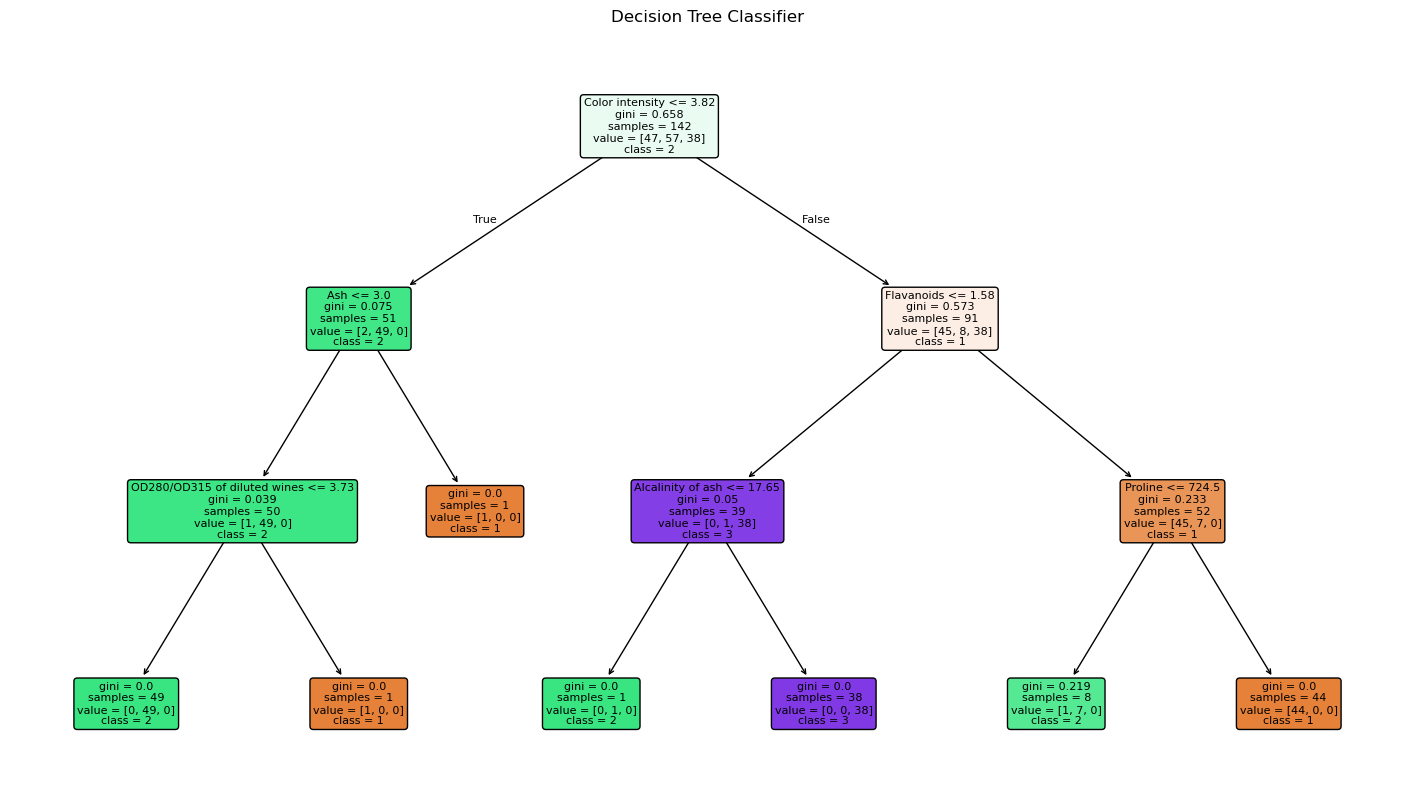

In [17]:
# Step 7: Visualize the Decision Tree

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")

plt.show()


Dataset shape: (178, 13)
Target classes: [np.int64(1), np.int64(2), np.int64(3)]

Accuracy: 0.9722222222222222

Confusion Matrix:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



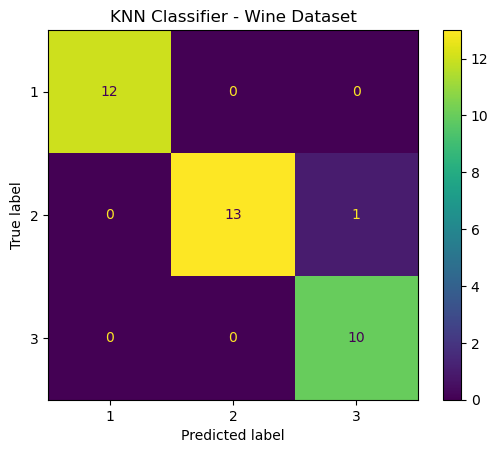

In [18]:

# KNN Classifier

# Step 1: Import the required libraries

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


# Step 2: Load the real-world dataset

data = pd.read_csv("Wine.csv")

X = data.drop("Class", axis=1)
y = data["Class"]

print("Dataset shape:", X.shape)
print("Target classes:", sorted(y.unique()))


# Step 3: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)


# Step 4: Create and train the KNN model

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

model.fit(X_train, y_train)


# Step 5: Make predictions

y_pred = model.predict(X_test)


# Step 6: Evaluate the model

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# Step 7: Visualize the Confusion Matrix

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("KNN Classifier - Wine Dataset")
plt.show()
print("Accuracy:", accuracy_score(y_test, y_pred))
y_pred = model.predict(X_test)
knn_pred = y_pred.copy()

Dataset shape: (178, 13)
Target classes: [np.int64(1), np.int64(2), np.int64(3)]

Accuracy: 0.9444444444444444

Confusion Matrix:
[[12  0  0]
 [ 1 13  0]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        12
           2       0.93      0.93      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



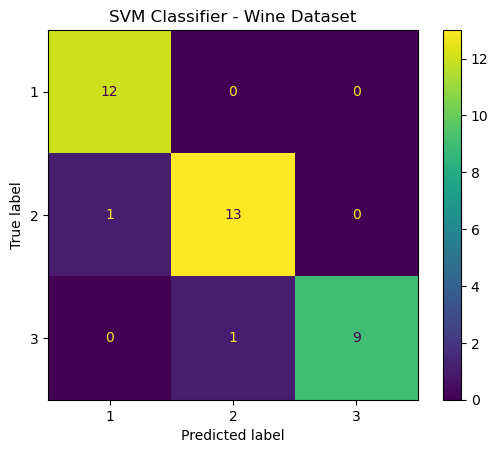

In [19]:

# SVM Classifier

# Step 1: Import the required libraries

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


# Step 2: Load the real-world dataset

data = pd.read_csv("Wine.csv")

X = data.drop("Class", axis=1)
y = data["Class"]

print("Dataset shape:", X.shape)
print("Target classes:", sorted(y.unique()))


# Step 3: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)


# Step 4: Create and train the SVM model

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="linear", random_state=42))
])

model.fit(X_train, y_train)


# Step 5: Make predictions

y_pred = model.predict(X_test)


# Step 6: Evaluate the model

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# Step 7: Visualize the Confusion Matrix

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("SVM Classifier - Wine Dataset")
plt.show()
print("Accuracy:", accuracy_score(y_test, y_pred))
y_pred = model.predict(X_test)
svm_pred = y_pred.copy()


Dataset shape: (178, 13)
Target classes: [np.int64(1), np.int64(2), np.int64(3)]

Accuracy: 1.0

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



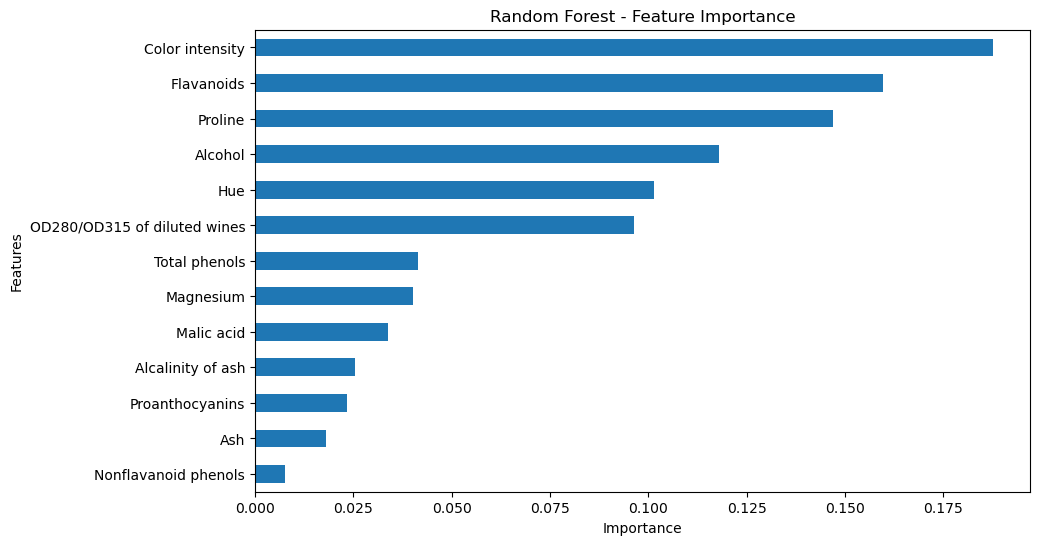

In [21]:

# Random Forest Classifier

# Step 1: Import the required libraries

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


# Step 2: Load the real-world dataset

data = pd.read_csv("Wine.csv")

X = data.drop("Class", axis=1)
y = data["Class"]

print("Dataset shape:", X.shape)
print("Target classes:", sorted(y.unique()))


# Step 3: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)


# Step 4: Create and train the Random Forest model

model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)


# Step 5: Make predictions

y_pred = model.predict(X_test)


# Step 6: Evaluate the model

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

#Visualise the importance of features
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(10, 6))

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()
print("Accuracy:", accuracy_score(y_test, y_pred))
y_pred = model.predict(X_test)
rf_pred = y_pred.copy()

In [23]:
# After running the KNN code
knn_pred = y_pred.copy()

# After running the SVM code
svm_pred = y_pred.copy()

# After running the Random Forest code
rf_pred = y_pred.copy()

In [24]:
print("KNN accuracy:", accuracy_score(y_test, knn_pred))
print("SVM accuracy:", accuracy_score(y_test, svm_pred))
print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))

KNN accuracy: 1.0
SVM accuracy: 1.0
Random Forest accuracy: 1.0


In [25]:
# Calculate the accuracy of each algorithm
knn_accuracy = accuracy_score(y_test, knn_pred)
svm_accuracy = accuracy_score(y_test, svm_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

# Create a comparison table
comparison = pd.DataFrame({
    "Algorithm": ["KNN", "SVM", "Random Forest"],
    "Accuracy": [knn_accuracy, svm_accuracy, rf_accuracy],
    "Accuracy (%)": [
        knn_accuracy * 100,
        svm_accuracy * 100,
        rf_accuracy * 100
    ]
})

# Display the comparison table
print("Algorithm Performance Comparison")
print(comparison.round(2).to_string(index=False))


Algorithm Performance Comparison
    Algorithm  Accuracy  Accuracy (%)
          KNN       1.0         100.0
          SVM       1.0         100.0
Random Forest       1.0         100.0
